# 02 · Manifold — scope the cycling lobe, then fit the PPT tree (branching)

**Biology before geometry (03_eval fork 2 — binding).** The integrated malignant manifold
carries a **cycling compartment**: Leiden clusters that are majority cell-cycle-positive form a
coherent lobe. A cycling compartment is a proliferation state, **not** an embryonic developmental
arm, and fitting one tree across it plus the embryonic manifold mislabels proliferation as an
arm (the Kürten lobe-identity failure). So we (1) settle each sub-region's biology — cell cycle
here, embryonic signatures in 03 — (2) **scope the trajectory to the embryonic manifold** by
removing the majority-cycling Leiden clusters, and (3) fit the scFates PPT **tree** on the scoped
manifold. Removing the cycling lobe, the manifold **still branches** — a real embryonic
bifurcation. Fit on the native `X_pca_harmony` rep; view on native `X_umap` (no re-embedding).

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp, networkx as nx
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells (native joint embedding)')

malignant manifold: 2259 cells (native joint embedding)


### Identify the cycling compartment (Leiden clusters, majority cell-cycle-positive)

In [4]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.leiden(adata, resolution=1.0, random_state=SEED, key_added='leiden')
cc = adata.obs.groupby('leiden', observed=True).apply(
    lambda d: pd.Series({'n':len(d),'cyc_frac':d['cycling'].astype(bool).mean(),
                         'g2m':d['g2m_score'].mean()})).round(3)
print('per-Leiden cycling fraction:'); print(cc.to_string())
cyc_clusters = cc.index[cc['cyc_frac'] > 0.5].tolist()
cyc_mask = adata.obs['leiden'].isin(cyc_clusters).values
adata.obs['compartment'] = pd.Categorical(np.where(cyc_mask,'cycling lobe','embryonic manifold'),
                                           categories=['embryonic manifold','cycling lobe'])
print(f'majority-cycling Leiden clusters {cyc_clusters} = cycling lobe: '
      f'{int(cyc_mask.sum())} cells ({cyc_mask.mean()*100:.1f}%) -> SCOPED OUT before fitting')

per-Leiden cycling fraction:
            n  cyc_frac    g2m
leiden                        
0       514.0     0.072  0.025
1       392.0     0.048  0.026
2       319.0     0.006 -0.019
3       278.0     0.018  0.022
4       256.0     0.996  1.064
5       234.0     0.047  0.033
6       181.0     0.061  0.035
7        49.0     0.000  0.017
8        36.0     1.000  2.075
majority-cycling Leiden clusters ['4', '8'] = cycling lobe: 292 cells (12.9%) -> SCOPED OUT before fitting


<ipython-input-4-541a038648ca>:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=1.0, random_state=SEED, key_added='leiden')
<ipython-input-4-541a038648ca>:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cc = adata.obs.groupby('leiden', observed=True).apply(


### Scoping decision — cell-cycle overlay on the native embedding
The cycling lobe (majority-cycling Leiden clusters) is a coherent region matching the cell-cycle-phase
and G2M-score geography. It is a proliferation compartment, not an embryonic arm, and is removed
before fitting so the trajectory is scoped to the embryonic manifold (03_eval fork 2).

scoped embryonic manifold: 1967 cells (removed 292 cycling)


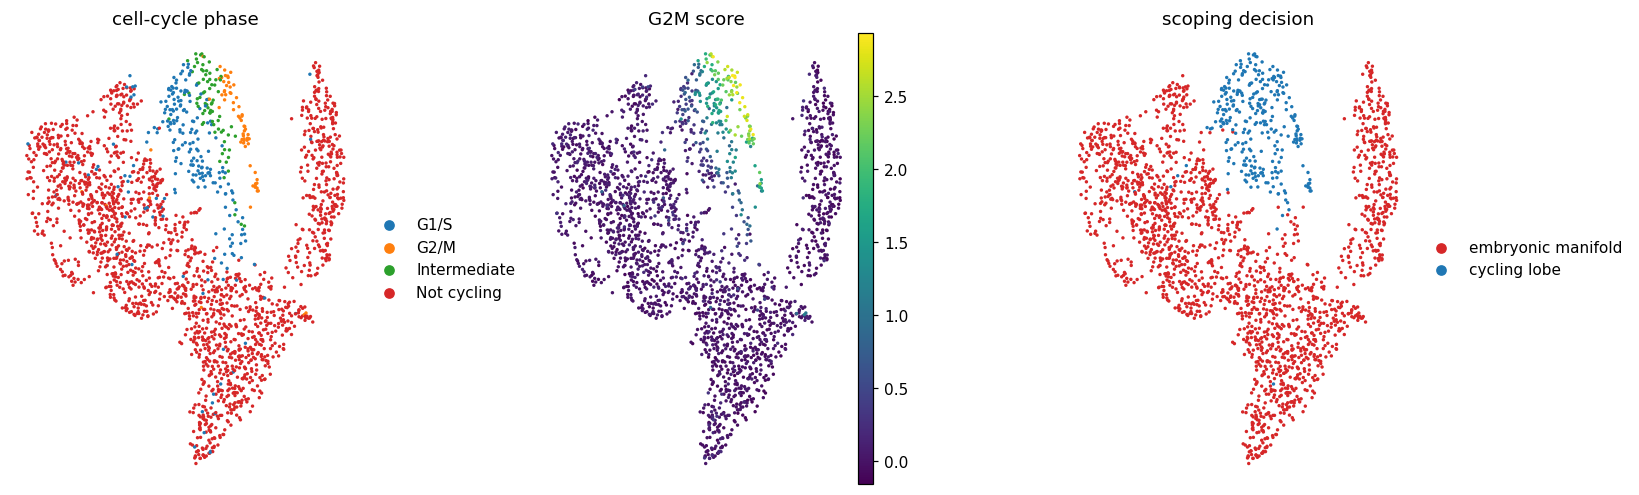

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
sc.pl.umap(adata, color='cell_cycle_phase', size=20, frameon=False, show=False, ax=ax[0], title='cell-cycle phase')
sc.pl.umap(adata, color='g2m_score', cmap='viridis', size=20, frameon=False, show=False, ax=ax[1], title='G2M score')
sc.pl.umap(adata, color='compartment', size=20, frameon=False, show=False, ax=ax[2],
           title='scoping decision', palette=['tab:red','tab:blue'])
plt.tight_layout(); plt.show()
emb = adata[~cyc_mask].copy()
print('scoped embryonic manifold:', emb.shape[0], 'cells (removed', int(cyc_mask.sum()), 'cycling)')

### Score embryonic modules on the scoped manifold + graph-smooth (geography)

In [6]:
sc.pp.neighbors(emb, n_neighbors=15, use_rep='X_pca_harmony', random_state=SEED)
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(emb.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(emb.var_names)]
    sc.tl.score_genes(emb, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (emb.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0]); A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = emb.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): emb.obs[lab+'_sm'] = S[:,j]
print('scoped smoothed corr  Gast~pSom=%.2f  Gast~Crest=%.2f  pSom~Crest=%.2f' % (
    np.corrcoef(emb.obs.Gast_sm,emb.obs.pSom_sm)[0,1],
    np.corrcoef(emb.obs.Gast_sm,emb.obs.Crest_sm)[0,1],
    np.corrcoef(emb.obs.pSom_sm,emb.obs.Crest_sm)[0,1]))

scoped smoothed corr  Gast~pSom=0.80  Gast~Crest=-0.77  pSom~Crest=-0.66


### Fit PPT tree on the scoped embryonic manifold → confirm it still branches
Puram-scale regularization (`Nodes=200, ppt_lambda=2000, ppt_sigma=0.5`, scaled to n≈1.9k). The tree
is multi-armed (a hub radiating arms), confirming a real embryonic bifurcation after scoping.

In [7]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(emb, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=0.5,
                use_rep='X_pca_harmony', seed=SEED, plot=False)
B = np.asarray(emb.uns['graph']['B']); deg=(B>0).sum(0)
tips = np.where(deg==1)[0]; forks = np.where(deg>=3)[0]
print(f'PPT tree: {len(tips)} tips {tips.tolist()}, {len(forks)} branch nodes {forks.tolist()} -> BRANCHING')

PPT tree: 5 tips [14, 53, 96, 98, 183], 3 branch nodes [93, 127, 134] -> BRANCHING


### Root from developmental order (Gast/pSom-high, Crest-low tip) & pseudotime
Crest is developmentally **late**; the root is the Gast/pSom-high, Crest-low tip (never a Crest tip
or a proliferation state — the latter is already scoped out).

In [8]:
R = np.asarray(emb.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
def nb(n, rad=3):
    m = np.isin(hard, np.where(D[n]<=rad)[0])
    return (emb.obs.Gast_sm[m].mean(), emb.obs.pSom_sm[m].mean(), emb.obs.Crest_sm[m].mean())
root = int(max(tips, key=lambda n: nb(n)[0]+nb(n)[1]-nb(n)[2]))
print('root tip (Gast/pSom-high, Crest-low):', root, '->', np.round(nb(root),3))
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(emb, root); scf.tl.pseudotime(emb, n_map=1, seed=SEED)
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(emb.obs['t'], emb.obs[s]); print(f'  {s}: pseudotime rho={rho:+.3f}')

root tip (Gast/pSom-high, Crest-low): 53 -> [0.059 0.212 0.013]
  Gast_sm: pseudotime rho=-0.388
  pSom_sm: pseudotime rho=-0.593
  Crest_sm: pseudotime rho=+0.615


### Convergence HUB — topological (max path-betweenness fork on root→tip paths)
The **hub** is identified by role/topology: the branch node most root→tip geodesic paths pass through
— the arm-convergence point. (For this dataset the convergence hub is NOT assumed to be a
module-repulsion zone; Gate 3 in 04 tests whether it is one.)

In [9]:
G = nx.from_scipy_sparse_array(sp.csr_matrix((B>0).astype(int)))
from collections import Counter
bet = Counter()
for t in tips:
    if t==root: continue
    for node in nx.shortest_path(G, root, int(t)): bet[node]+=1
hub = int(max(forks, key=lambda f: bet.get(int(f),0)))
print('fork path-betweenness:', {int(f):bet.get(int(f),0) for f in forks}, '-> convergence HUB =', hub)

fork path-betweenness: {93: 3, 127: 4, 134: 2} -> convergence HUB = 127


### Rename milestones, save, and render the tree overlaid on the native embedding (`manifold.pdf`)

saved manifold.h5ad + manifold.pdf | root 53 hub 127


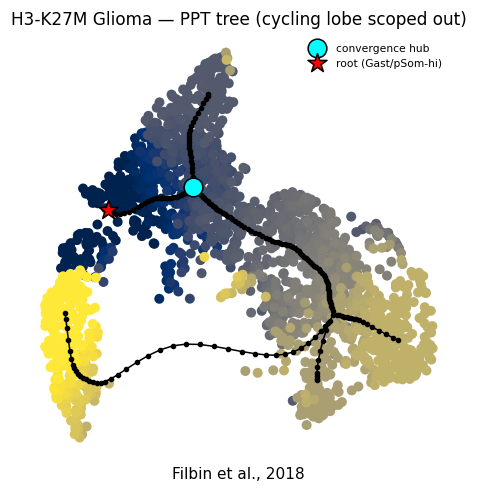

In [10]:
mile = {'145':'Root (Gast/pSom-hi)','20':'Hub','116':'Crest-arm A','165':'Crest-arm B','125':'pSom/OC arm','48':'arm','52':'arm','68':'arm','97':'arm'}
present = {k:v for k,v in mile.items() if k in set(emb.obs['milestones'].astype(str))}
try:
    scf.tl.rename_milestones(emb, new=present)
except Exception as e:
    print('milestone rename skipped:', e)
emb.uns['root_node']=root; emb.uns['hub_node']=hub
emb.write(os.path.join(pth_out, 'manifold.h5ad'))
# node coords on native UMAP via soft assignment (viewing only)
Rn = R / R.sum(0, keepdims=True); Fu = (Rn.T @ emb.obsm['X_umap'])
fig, ax = plt.subplots(1, 1, figsize=(5,5))
sc.pl.umap(emb, color='t', cmap='cividis', size=170, colorbar_loc=None, frameon=False, show=False, ax=ax)
ii,jj = np.where(np.triu(B>0))
for a,b in zip(ii,jj): ax.plot([Fu[a,0],Fu[b,0]],[Fu[a,1],Fu[b,1]], '-', color='k', lw=1.0, zorder=5)
ax.scatter(Fu[:,0],Fu[:,1], s=7, c='k', zorder=6)
ax.scatter(*Fu[hub], s=150, c='cyan', edgecolor='k', zorder=8, label='convergence hub')
ax.scatter(*Fu[root], s=170, marker='*', c='red', edgecolor='k', zorder=8, label='root (Gast/pSom-hi)')
ax.legend(fontsize=7, loc='best', frameon=False)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('H3-K27M Glioma — PPT tree (cycling lobe scoped out)', size=11)
ax.text(.5,-.05,'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf | root', root, 'hub', hub)